# Within-region group comparison: false positive rate

`compare_within_region()` tests in every parcel whether two groups (or two sessions) differ,
like a t-test, or an ANCOVA when covariates were regressed out with `clean_y()`. Its p-values
come from the group-permutation null maps that `permute(what="groups")` also uses for
colocalization.

When covariates were regressed out of Y and are associated with group (e.g. patients are
older, or head motion is higher in the second session), shuffling the group labels of the
cleaned data gives a null distribution that is too narrow: shuffling removes the association
between group and covariate, and with it the extra variance of the group effect that this
association causes. NiSpace therefore uses the Freedman–Lane procedure (Freedman & Lane, 1983;
Winkler et al., 2014) whenever between-subject covariates were regressed: it permutes the
residuals of the covariates-only model, adds the fitted values back, repeats the covariate
regression and recomputes the transform with the original labels.

This notebook checks, under the null hypothesis (no group effect, but a covariate effect):

1. the per-parcel false positive rate and the family-wise error rate (FWER) of
   `compare_within_region()` for unpaired designs, with a covariate correlated with group
   (r = 0 to 0.8), and for paired pre/post designs with a scan-level covariate (head motion)
   that is higher in the second session;
2. the same for label shuffling of the cleaned data (the scheme NiSpace used before
   Freedman–Lane);
3. the false positive rate of the colocalization test (`permute(what="groups")`) in the same
   settings.

## Benchmark design

Subject maps are Gaussian random field (GRF) maps in the Yan200 parcellation (`alpha = 2`,
spatially smooth; each map z-scored), so neighbouring parcels are correlated as in real data.

- **Unpaired:** 20 + 20 subjects. A covariate (e.g. age) correlates with group at r
  (0, 0.3, 0.6, 0.8) and affects Y with a spatially varying slope; there is no group effect.
  Cleaning: `clean_y(how="between", covariates_between=age, protect=groups)`, then
  `transform_y("hedges(PAT,HC)")`.
- **Paired:** 20 subjects, two sessions, subject-specific maps. Head motion is higher in
  the second session by Δ SD (0, 0.5, 1, 2) and affects Y; age and sex are constant within
  subjects. Cleaning with motion, age and sex, protecting session and subject; transform
  `pairedcohen(post,pre)`.
- **Colocalization:** an independent GRF map as X, `colocalize("pearson")` and
  `permute("groups")`.

Each condition has `N_REPS` repetitions with `N_PERM` permutations. Metrics: per-parcel
false positive rate (uncorrected p < 0.05, pooled over parcels and repetitions); FWER (any
parcel with corrected p < 0.05; step-down minP, the default, and step-down maxT); and the
rejection rate of the colocalization test. Label shuffling is computed from the same cleaned
data with the same permutations' random generator.

In [1]:
# ── Configuration ─────────────────────────────────────────────────────────────
PARC = "Yan200"
GRF_ALPHA = 2.0
N_PER_GROUP = 20
R_GROUP_COV = [0.0, 0.3, 0.6, 0.8]       # unpaired: r(group, covariate)
MOTION_SHIFT = [0.0, 0.5, 1.0, 2.0]      # paired: second-session motion shift (SD)
N_REPS = 200
N_PERM = 10000
P_THRESH = 0.05
SEED = 42
N_JOBS = 8

import time
import warnings
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from nispace import NiSpace
from nispace.datasets import fetch_reference
from nispace.core.group_nulls import generate_group_nulls
from nispace.core.transform_y import _get_transform_fun
from nispace.stats.misc import (_augmented_column_p, step_minP_correction,
                                step_maxT_correction, null_to_p)

grf = fetch_reference("grf", parcellation=PARC, collection="ByAlpha", verbose=False)
POOL = grf.loc[f"alpha-{GRF_ALPHA}"].to_numpy(dtype=float)
POOL = (POOL - POOL.mean(1, keepdims=True)) / POOL.std(1, keepdims=True)
PARCELS = list(grf.columns)
print(f"GRF pool: {POOL.shape[0]} maps x {POOL.shape[1]} parcels")

GRF pool: 10000 maps x 200 parcels


In [2]:
# ── Helper functions ──────────────────────────────────────────────────────────

def _draw(rng, k):
    return POOL[rng.choice(len(POOL), k, replace=False)]


def _family(obs, cube, mc):
    fn = {"step_minP": step_minP_correction, "step_maxT": step_maxT_correction}[mc]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        p_corr, _ = fn(obs[np.newaxis, :], [{"s": cube[b][np.newaxis, :]} for b in range(len(cube))],
                       stat="s", tail="two", how="r")
    return np.asarray(p_corr)[0]


def _metrics(prefix, p_raw, p_minp, p_maxt, p_coloc):
    return {f"{prefix}_fpr": float(np.mean(p_raw < P_THRESH)),
            f"{prefix}_fwer_step_minP": float(np.any(p_minp < P_THRESH)),
            f"{prefix}_fwer_step_maxT": float(np.any(p_maxt < P_THRESH)),
            f"{prefix}_coloc": float(p_coloc < P_THRESH)}


def one_rep(paired, level, seed):
    """One repetition: Freedman-Lane (compare_within_region / permute) and label shuffling
    of the cleaned data, both from the same data."""
    logging.getLogger("nispace").setLevel(logging.ERROR)
    rng = np.random.default_rng(seed)
    n = 2 * N_PER_GROUP
    g = np.r_[np.zeros(N_PER_GROUP), np.ones(N_PER_GROUP)].astype(int)
    labels = np.where(g == 0, "HC", "PAT") if not paired else np.where(g == 0, "pre", "post")
    slope = 1 + 0.5 * _draw(rng, 1)[0]                     # spatially varying covariate effect
    if not paired:
        cov = level * (g - 0.5) / 0.5 + np.sqrt(1 - level ** 2) * rng.normal(size=n)
        Y = cov[:, None] * slope + _draw(rng, n)
        covariates = pd.DataFrame({"age": cov})
        protect = pd.DataFrame({"groups": labels})
        formula, subjects = "hedges(PAT,HC)", None
    else:
        subj = np.r_[np.arange(N_PER_GROUP), np.arange(N_PER_GROUP)]
        motion = rng.normal(size=n) + level * g
        age = rng.normal(size=N_PER_GROUP)[subj]
        sex = rng.integers(0, 2, N_PER_GROUP)[subj].astype(float)
        Y = (_draw(rng, N_PER_GROUP)[subj] + motion[:, None] * slope
             + 0.5 * age[:, None] + 0.3 * sex[:, None] + _draw(rng, n))
        covariates = pd.DataFrame({"motion": motion, "age": age, "sex": sex})
        subjects = subj.astype(str)
        protect = pd.DataFrame({"groups": labels, "subjects": subjects})
        formula = "pairedcohen(post,pre)"
    y_df = pd.DataFrame(Y, index=[f"s{i}" for i in range(n)], columns=PARCELS)
    x_df = pd.DataFrame(_draw(rng, 1), index=["X"], columns=PARCELS)   # independent X
    nsp = NiSpace(x=x_df, y=y_df, parcellation=None, standardize=False, n_proc=1,
                  verbose=False, return_self=True)
    nsp.fit()
    nsp.clean_y("between", covariates_between=covariates, protect=protect)
    nsp.transform_y(formula, groups=labels, subjects=subjects, verbose=False)

    # Freedman-Lane: compare_within_region() and permute() share the null maps
    nsp.compare_within_region(n_perm=N_PERM, seed=seed, verbose=False)
    res = nsp.get_within_region_comparisons(mc_method=None, verbose=False)
    obs = res["stat"].to_numpy(dtype=float)[0]
    cube_fl = nsp._nulls["groups_null"].data[0].astype(float)
    nsp.colocalize("pearson", verbose=False)
    nsp.permute("groups", n_perm=N_PERM, verbose=False)
    p_coloc_fl = float(nsp.get_p_values(verbose=False).to_numpy().ravel()[0])
    out = _metrics("fl", res["p"].to_numpy()[0], _family(obs, cube_fl, "step_minP"),
                   _family(obs, cube_fl, "step_maxT"), p_coloc_fl)

    # label shuffling of the cleaned data
    design = nsp._get_transform_design(formula.lower())
    at = _get_transform_fun("pairedcohen(b,a)" if paired else "hedges(b,a)", return_df=False,
                            dtype=np.float32, ignore_nan_warnings=True)
    cube_lab = generate_group_nulls(nsp._Y.to_numpy(np.float32), g, design["subjects_no_nan"],
                                    at, N_PERM, seed=seed, paired=paired, verbose=False)[0]
    cube_lab = cube_lab.astype(float)
    p_lab = _augmented_column_p(obs, cube_lab, "two")[0]
    x = x_df.to_numpy()[0]
    r_obs = np.corrcoef(obs, x)[0, 1]
    cz = (cube_lab - cube_lab.mean(1, keepdims=True)) / cube_lab.std(1, keepdims=True)
    r_null = cz @ ((x - x.mean()) / x.std()) / len(x)
    out |= _metrics("labels", p_lab, _family(obs, cube_lab, "step_minP"),
                    _family(obs, cube_lab, "step_maxT"), null_to_p(r_obs, r_null, "two"))
    return out


def run(paired, levels):
    rows = []
    for level in levels:
        t0 = time.time()
        reps = Parallel(n_jobs=N_JOBS)(
            delayed(one_rep)(paired, level, SEED + 1000 * i + int(100 * level))
            for i in range(N_REPS))
        row = pd.DataFrame(reps).mean().to_dict()
        rows.append({"design": "paired" if paired else "unpaired", "level": level} | row)
        print(f"{'paired' if paired else 'unpaired'} level={level}: {time.time() - t0:.0f} s")
    return pd.DataFrame(rows)

In [3]:
# ── Run all conditions ────────────────────────────────────────────────────────
t_start = time.time()
results = pd.concat([run(False, R_GROUP_COV), run(True, MOTION_SHIFT)], ignore_index=True)
print(f"Total: {(time.time() - t_start) / 60:.1f} min")

n_pooled = N_REPS * len(PARCELS)
ci_parcel = 1.96 * np.sqrt(P_THRESH * (1 - P_THRESH) / n_pooled)
ci_rep = 1.96 * np.sqrt(P_THRESH * (1 - P_THRESH) / N_REPS)
print(f"95% CI per-parcel FPR (n={n_pooled}, ignoring spatial dependence): "
      f"[{P_THRESH - ci_parcel:.3f}, {P_THRESH + ci_parcel:.3f}]")
print(f"95% CI FWER / colocalization (n={N_REPS}): "
      f"[{P_THRESH - ci_rep:.3f}, {P_THRESH + ci_rep:.3f}]")

unpaired level=0.0: 170 s


unpaired level=0.3: 147 s


unpaired level=0.6: 149 s


unpaired level=0.8: 152 s


paired level=0.0: 187 s


paired level=0.5: 225 s


paired level=1.0: 173 s


paired level=2.0: 177 s
Total: 23.0 min
95% CI per-parcel FPR (n=40000, ignoring spatial dependence): [0.048, 0.052]
95% CI FWER / colocalization (n=200): [0.020, 0.080]


## Results

In [4]:
cols = ["design", "level",
        "fl_fpr", "labels_fpr",
        "fl_fwer_step_minP", "labels_fwer_step_minP",
        "fl_fwer_step_maxT", "labels_fwer_step_maxT",
        "fl_coloc", "labels_coloc"]
results[cols].round(3)

,design,level,fl_fpr,labels_fpr,fl_fwer_step_minP,labels_fwer_step_minP,fl_fwer_step_maxT,labels_fwer_step_maxT,fl_coloc,labels_coloc
0,unpaired,0.0,0.044,0.049,0.040,0.050,0.040,0.050,0.055,0.060
1,unpaired,0.3,0.048,0.066,0.035,0.070,0.045,0.070,0.010,0.015
2,unpaired,0.6,0.050,0.129,0.065,0.310,0.080,0.345,0.030,0.035
3,unpaired,0.8,0.049,0.242,0.040,0.720,0.065,0.755,0.070,0.060
4,paired,0.0,0.052,0.064,0.060,0.090,0.060,0.105,0.040,0.030
5,paired,0.5,0.047,0.079,0.020,0.090,0.050,0.145,0.030,0.035
6,paired,1.0,0.044,0.117,0.025,0.245,0.035,0.235,0.050,0.050
7,paired,2.0,0.050,0.270,0.040,0.775,0.065,0.785,0.090,0.065


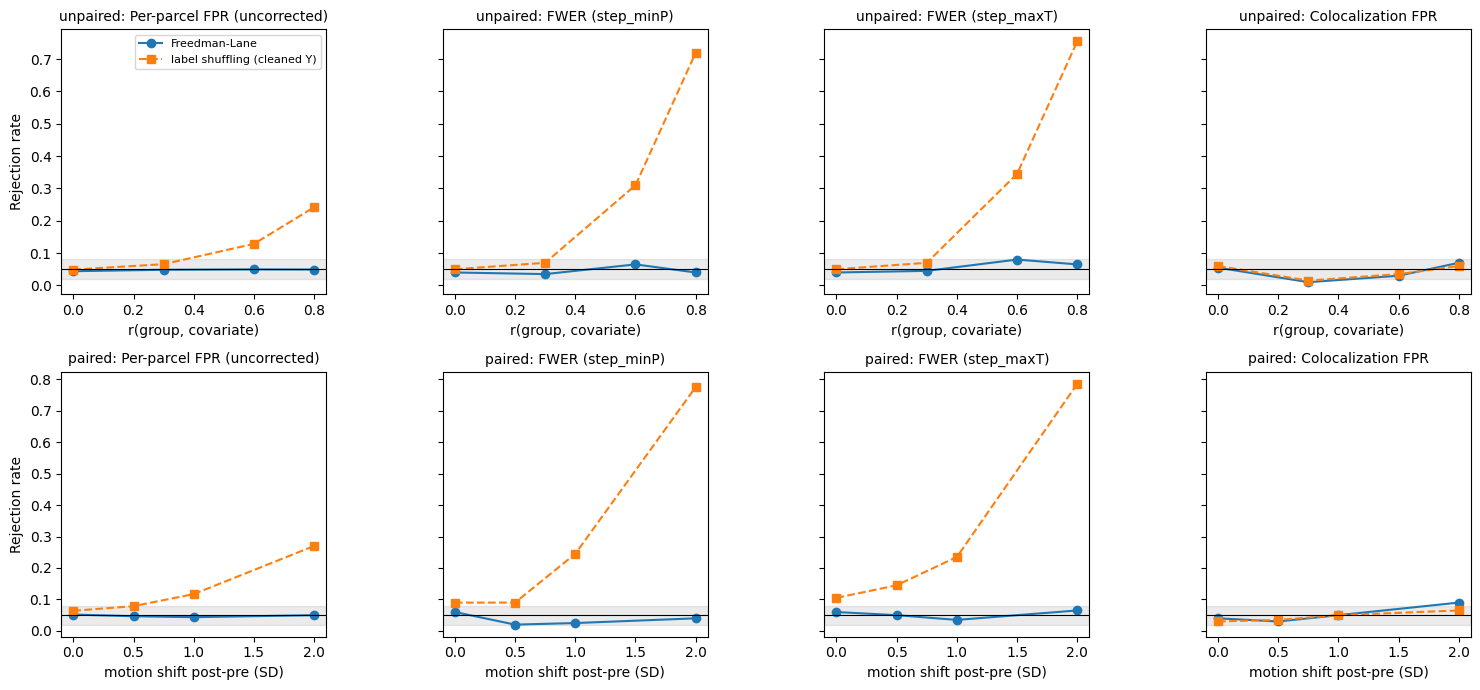

In [5]:
METRICS = [("fpr", "Per-parcel FPR (uncorrected)"), ("fwer_step_minP", "FWER (step_minP)"),
           ("fwer_step_maxT", "FWER (step_maxT)"), ("coloc", "Colocalization FPR")]
fig, axes = plt.subplots(2, len(METRICS), figsize=(4 * len(METRICS), 7), sharey="row")
for row, (design, xlabel) in enumerate([("unpaired", "r(group, covariate)"),
                                        ("paired", "motion shift post-pre (SD)")]):
    sub = results[results.design == design]
    for ax, (m, title) in zip(axes[row], METRICS):
        ax.plot(sub.level, sub[f"fl_{m}"], "o-", label="Freedman-Lane")
        ax.plot(sub.level, sub[f"labels_{m}"], "s--", label="label shuffling (cleaned Y)")
        ax.axhline(P_THRESH, color="k", lw=0.8)
        ax.axhspan(P_THRESH - ci_rep, P_THRESH + ci_rep, color="k", alpha=0.08)
        ax.set_xlabel(xlabel)
        ax.set_title(f"{design}: {title}", fontsize=10)
        ax.set_box_aspect(1)
    axes[row, 0].set_ylabel("Rejection rate")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()

## Interpretation

**Freedman–Lane keeps the error rates at their nominal level.** The per-parcel false positive
rate of `compare_within_region()` stays between 0.044 and 0.052 in all conditions: unpaired
designs with a covariate correlated with group up to r = 0.8, and paired designs with head
motion up to 2 SD higher in the second session. The family-wise error rate (any parcel
significant after correction) stays within or at the edge of the 95% band for 200 repetitions
(0.02–0.08), for both step-down minP (the default) and step-down maxT.

**Label shuffling of the cleaned data is anti-conservative as soon as covariates are
associated with group.** Its per-parcel false positive rate grows with the association
(unpaired: 0.066, 0.129, 0.242 for r = 0.3, 0.6, 0.8; paired: 0.079, 0.117, 0.270 for motion
shifts of 0.5, 1, 2 SD), and its family-wise error rate reaches 0.72–0.79. This was NiSpace's
scheme before Freedman–Lane. Re-running the covariate regression after every shuffle does not
fix it (checked in a separate simulation): shuffling removes the association between group and
covariate, and with it the extra variance of the group effect that this association causes.

**Colocalization p-values are not systematically affected.** The colocalization test
(`permute(what="groups")`) rejects at similar rates with both schemes (0.010–0.09), with no
trend over the strength of the association. This is expected: a spatial correlation does not
depend on the scale of the group-effect map, and the scale is what label shuffling gets wrong.
Single values outside the 95% band (Freedman–Lane, paired, 2 SD: 0.090) are compatible with
chance across 16 rates of 200 repetitions each.

**Limits of this benchmark.** One smoothness level (GRF alpha = 2), 20 subjects per group or
20 subjects with two sessions, one parcellation (Yan200), linear covariate effects, no ComBat
(ComBat is treated as fixed preprocessing in the permutation, and NiSpace warns about it). The
default correction, step-down minP, needs many permutations with many parcels: with 200 parcels
and 1000 permutations no parcel can reach a corrected p < 0.05 (NiSpace warns), so this
benchmark uses 10000.